# Example of the aitlas toolbox in the context of multi class image classification

Most samples include paired Sentinel-2 and Landsat 8 images with matching timestamps and spatial extent. This notebook covers three use cases: using Sentinel-2 images only, treating Sentinel-2 and Landsat 8 images as seperate individual images (unpaired), and treating them as paired images where available. 

## Import the required packages

In [ ]:
from aitlas.datasets import BrazilDAMDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

### Both Sentinel and Landsat imagery

Specific bands

In [39]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_train.csv",
    "imagery": "sentinel and landsat paired",
    "selection": "bands",
    "bands_s2": ["B01","B02","B03","B04","B05","B06"],
    "bands_l8": ["B02","B03","B04"]
}
dataset = BrazilDAMDataset(dataset_config)
print(len(dataset))

4215


RGB images paired

4215


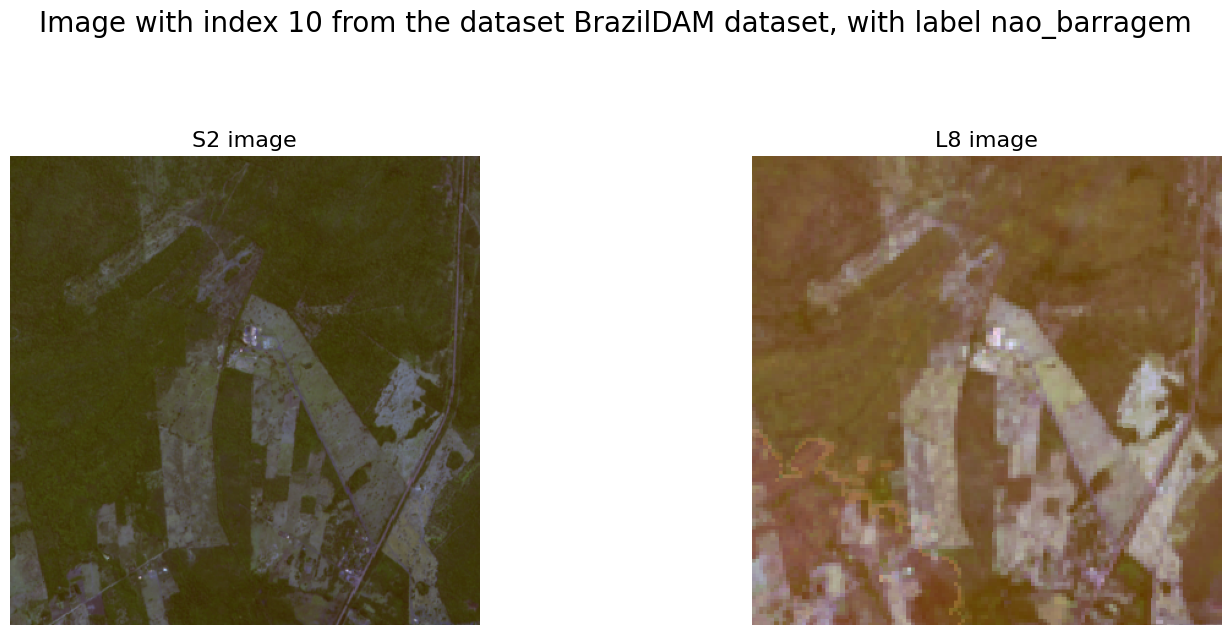

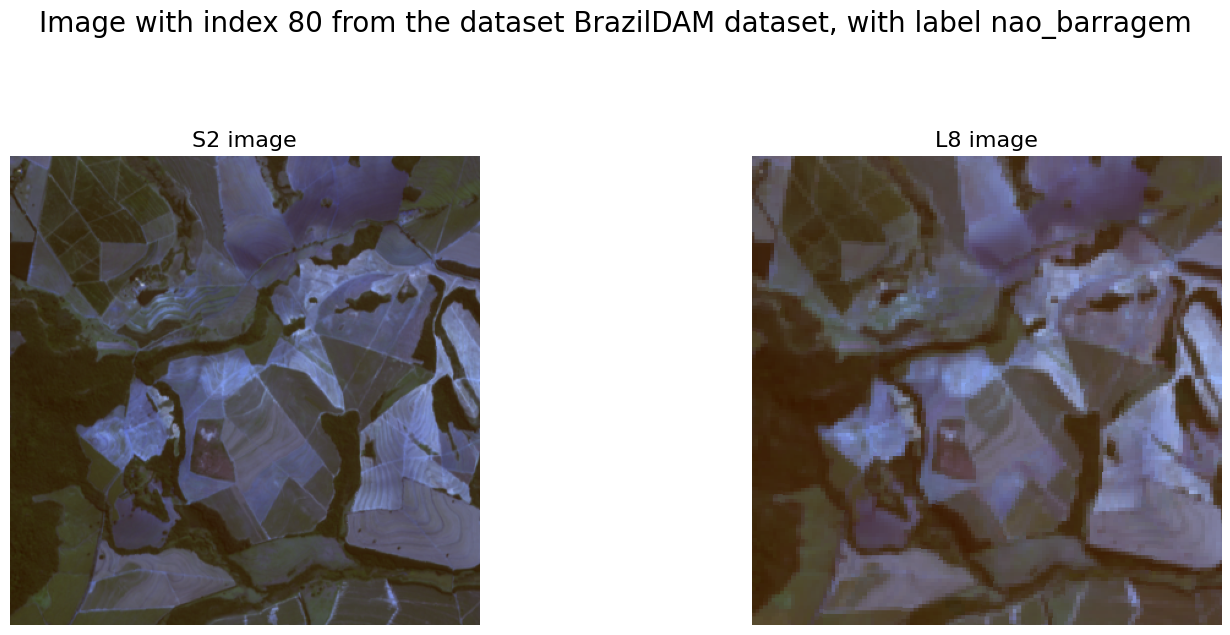

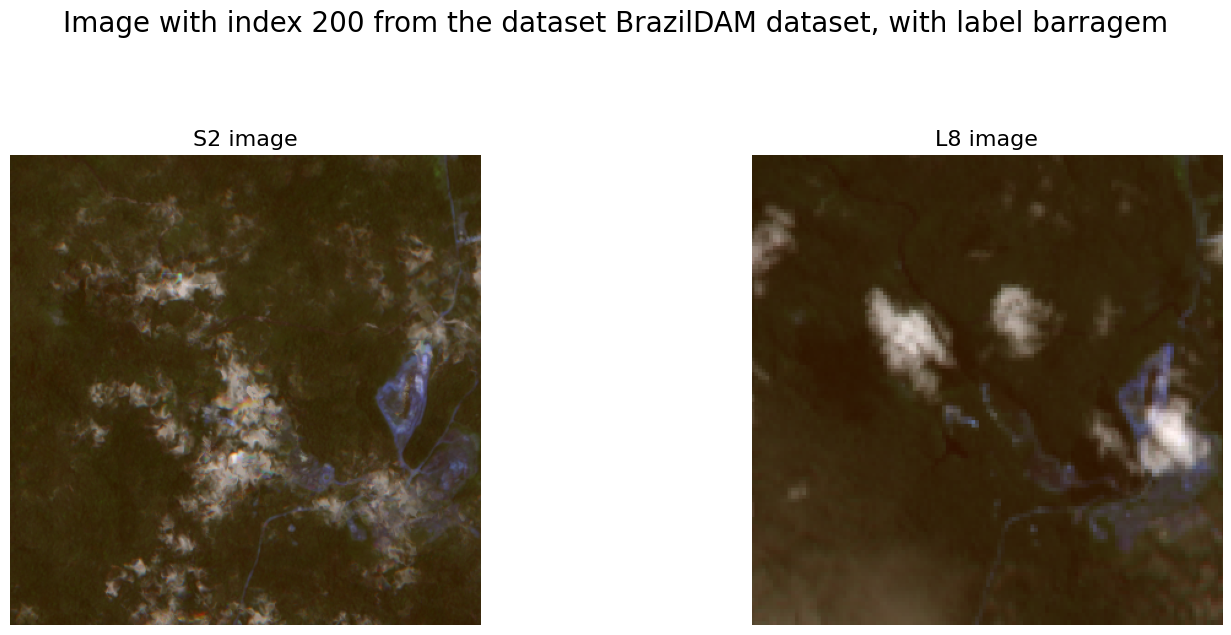

In [40]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_train.csv",
    "imagery": "sentinel and landsat paired",
    "selection": "rgb"
}
dataset = BrazilDAMDataset(dataset_config)
print(len(dataset))

fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

RGB images unpaired

8833


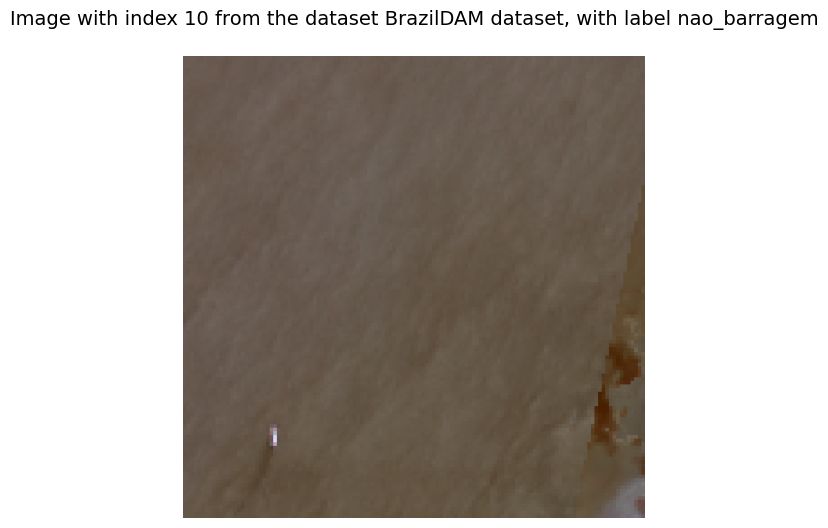

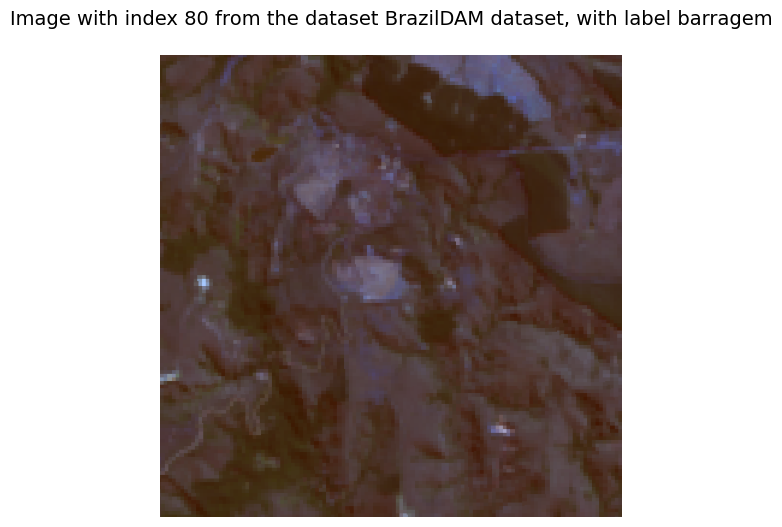

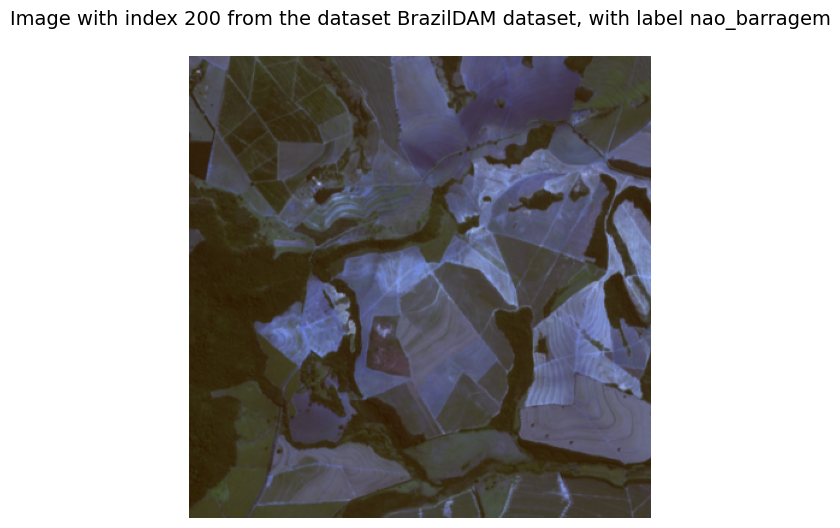

In [41]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_train.csv",
    "imagery": "sentinel and landsat unpaired",
    "selection": "rgb"
}
dataset = BrazilDAMDataset(dataset_config)
print(len(dataset))

fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

### Sentinel imagery

4619


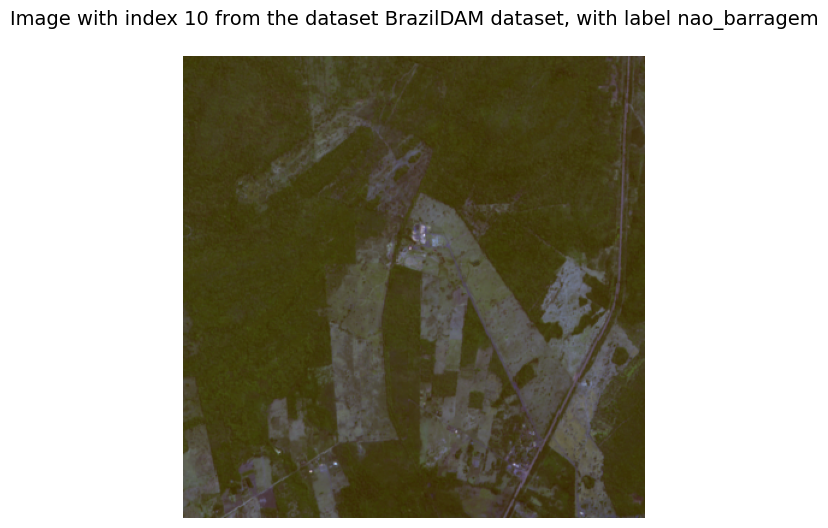

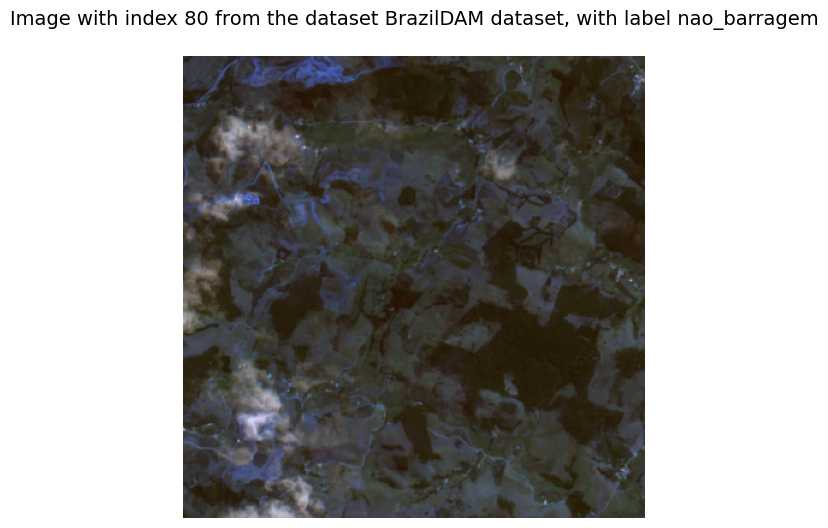

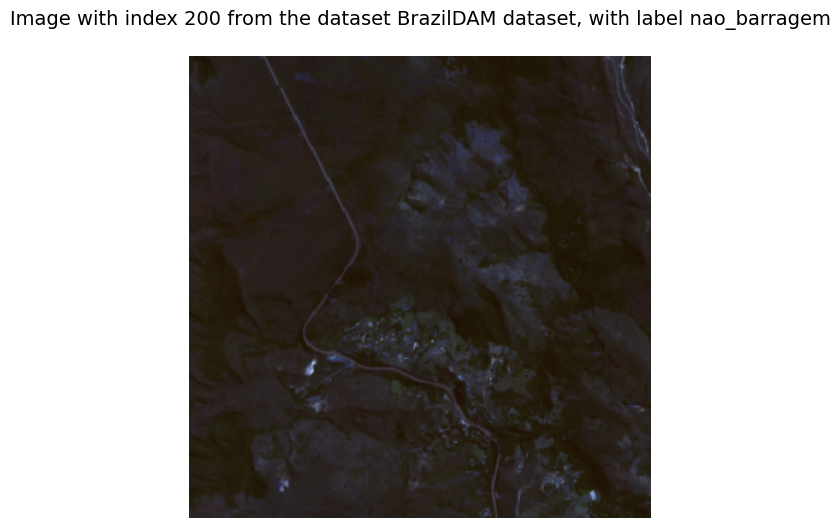

In [42]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_train.csv",
    "imagery": "sentinel"
}
dataset = BrazilDAMDataset(dataset_config)
print(len(dataset))

fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

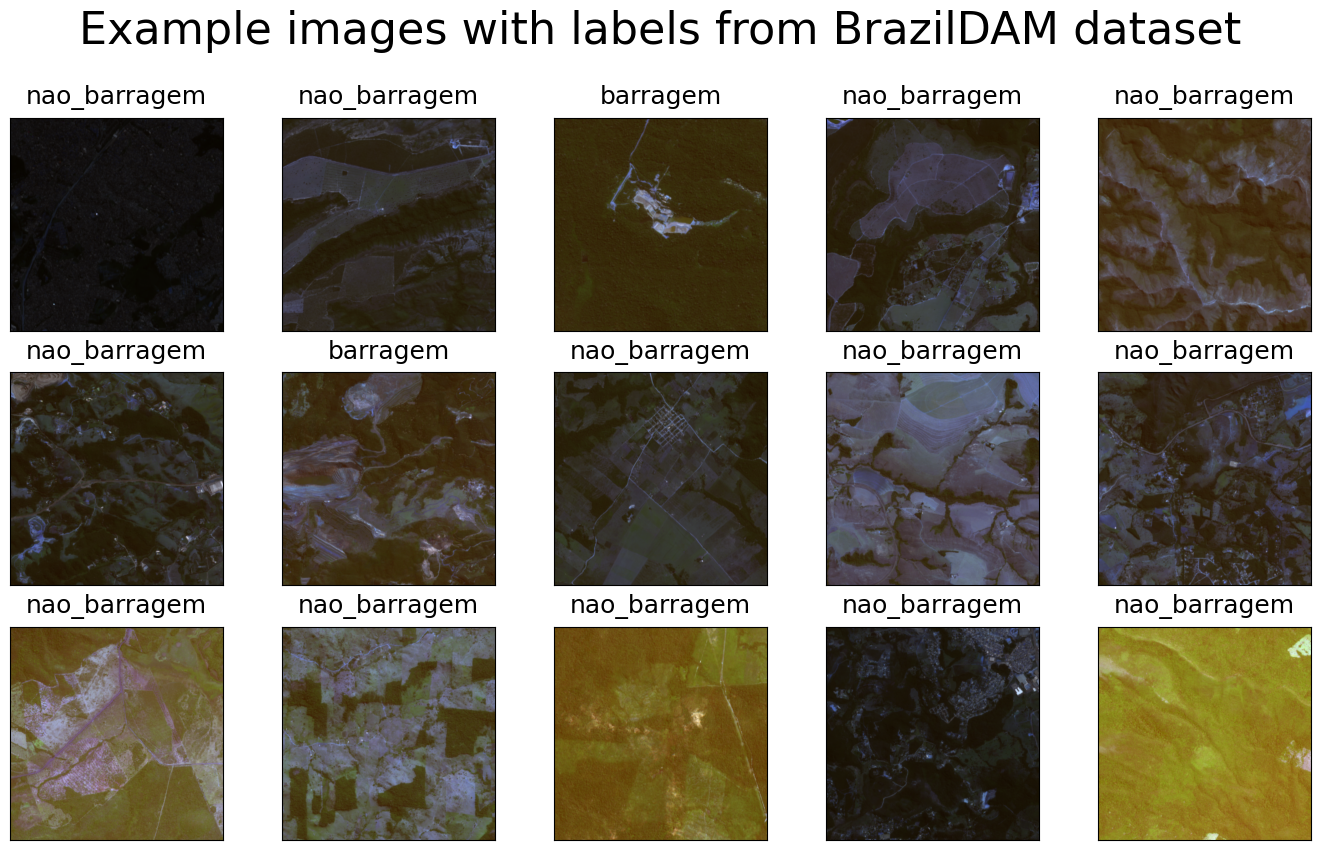

In [13]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [23]:
dataset.show_samples()

,File_name,Label
0,S443_2017.tif,nao_barragem
1,320_2019.tif,barragem
2,255_2018.tif,barragem
3,751_2018.tif,barragem
4,N117_2017.tif,nao_barragem
5,N636_2017.tif,nao_barragem
6,N518_2017.tif,nao_barragem
7,N332_2017.tif,nao_barragem
8,N693_2017.tif,nao_barragem
9,S290_2016.tif,nao_barragem


In [30]:
dataset.data_distribution_table()

,Label,Count
0,nao_barragem,2776
1,barragem,1843


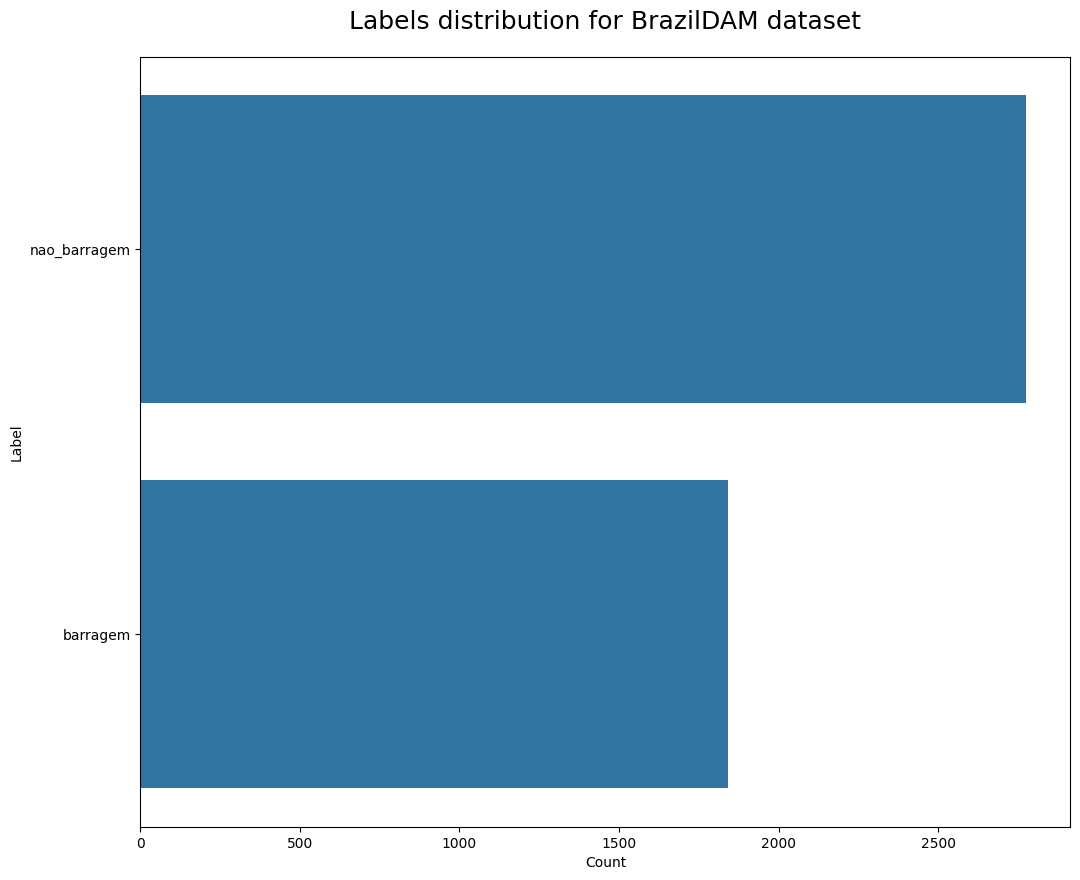

In [31]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [32]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_train.csv",
    "imagery": "sentinel"
}

train_dataset = BrazilDAMDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_val.csv",
    "imagery": "sentinel",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = BrazilDAMDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(4619, 1539)

## Setup and create the model for training

In [66]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/BrazilDAM/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2026-03-23 10:20:14,007 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2026-03-23 10:20:14,157 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [59]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-19 13:35:19,821 INFO Starting training.
training: 100%|██████████| 193/193 [01:51<00:00,  1.73it/s]
2025-05-19 13:37:11,676 INFO epoch: 1, time: 111, loss:  0.33839
testing on train set: 100%|██████████| 193/193 [00:41<00:00,  4.60it/s]
2025-05-19 13:37:55,658 INFO Accuracy:0.9257996427991557, Precision Micro:0.9257996427991557, Precision Macro:0.923318454656084, Precision Weighted:0.9256900396671693, Precision per Class:[0.93495717 0.91167974], Recall Micro:0.9257996427991557, Recall Macro:0.9215843026134147, Recall Weighted:0.9257996427991557, Recall per Class:[0.94227138 0.90089723], F1_score Micro:0.9257996427991553, F1_score Macro:0.9224282185636472, F1_score Weighted:0.9257234969246773, F1_score per Class:[0.93860003 0.90625641]
testing on validation set: 100%|██████████| 25/25 [00:06<00:00,  4.05it/s]
2025-05-19 13:38:01,839 INFO Accuracy:0.9193758127438232, Precision Micro:0.9193758127438232, Precision Macro:0.9174902561247216, Precision Weighted:0.919317345871913, Prec

0.09860791447662381

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/BrazilDAM/",
    "csv_file": "/home/dragik/data/FAIR_EO/BrazilDAM/splits_final/brazildam_test.csv",
    "imagery": "sentinel",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = BrazilDAMDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-19 13:54:35,389 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar
2025-05-19 13:54:35,653 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 49/49 [00:05<00:00,  8.56it/s]


[{'Accuracy': 0.9557867360208062},
 {'Precision Micro': 0.9557867360208062,
  'Precision Macro': 0.9591215576623414,
  'Precision Weighted': 0.956372363235905,
  'Precision per Class': array([0.94661191, 0.97163121])},
 {'Recall Micro': 0.9557867360208062,
  'Recall Macro': 0.948137882018479,
  'Recall Weighted': 0.9557867360208061,
  'Recall per Class': array([0.98294243, 0.91333333])},
 {'F1_score Micro': 0.9557867360208057,
  'F1_score Macro': 0.9530079512286296,
  'F1_score Weighted': 0.9555192594097941,
  'F1_score per Class': array([0.96443515, 0.94158076])}]

## Predictions

2025-11-17 12:43:03,048 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar
2025-11-17 12:43:03,863 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar at epoch 11


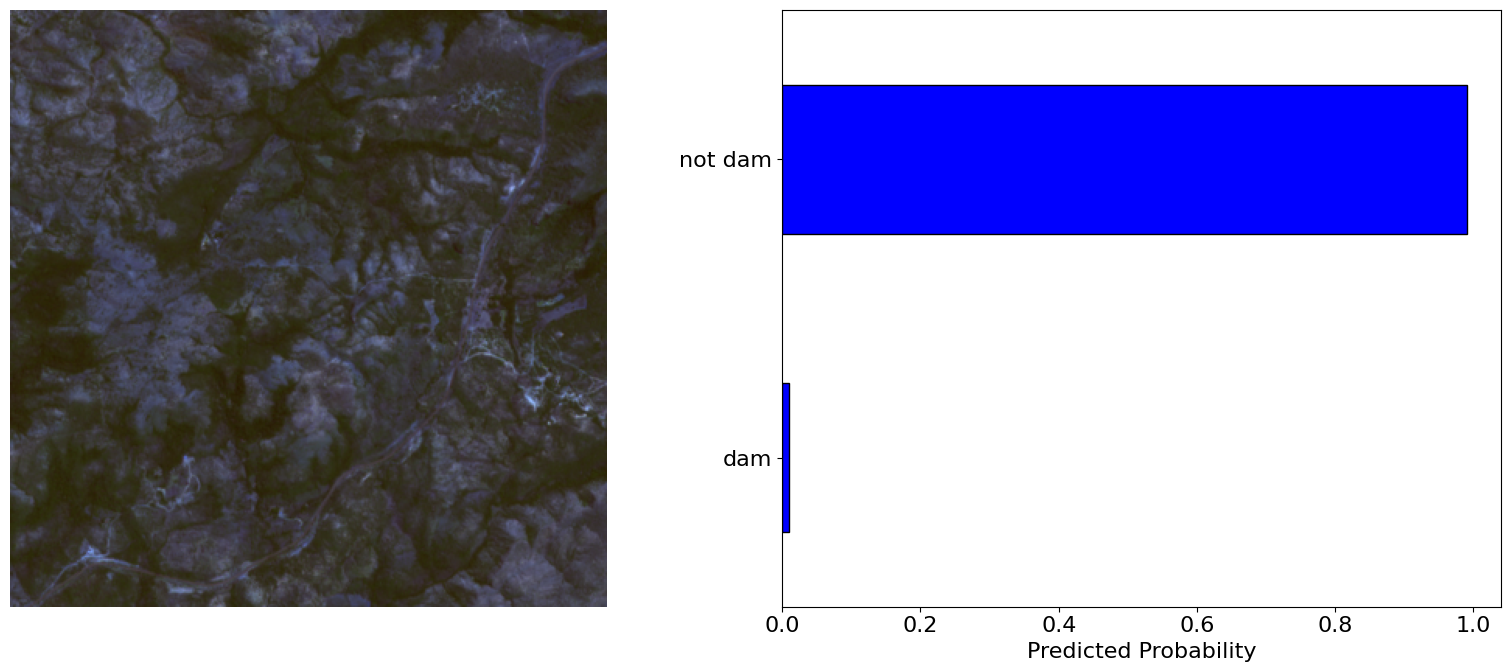

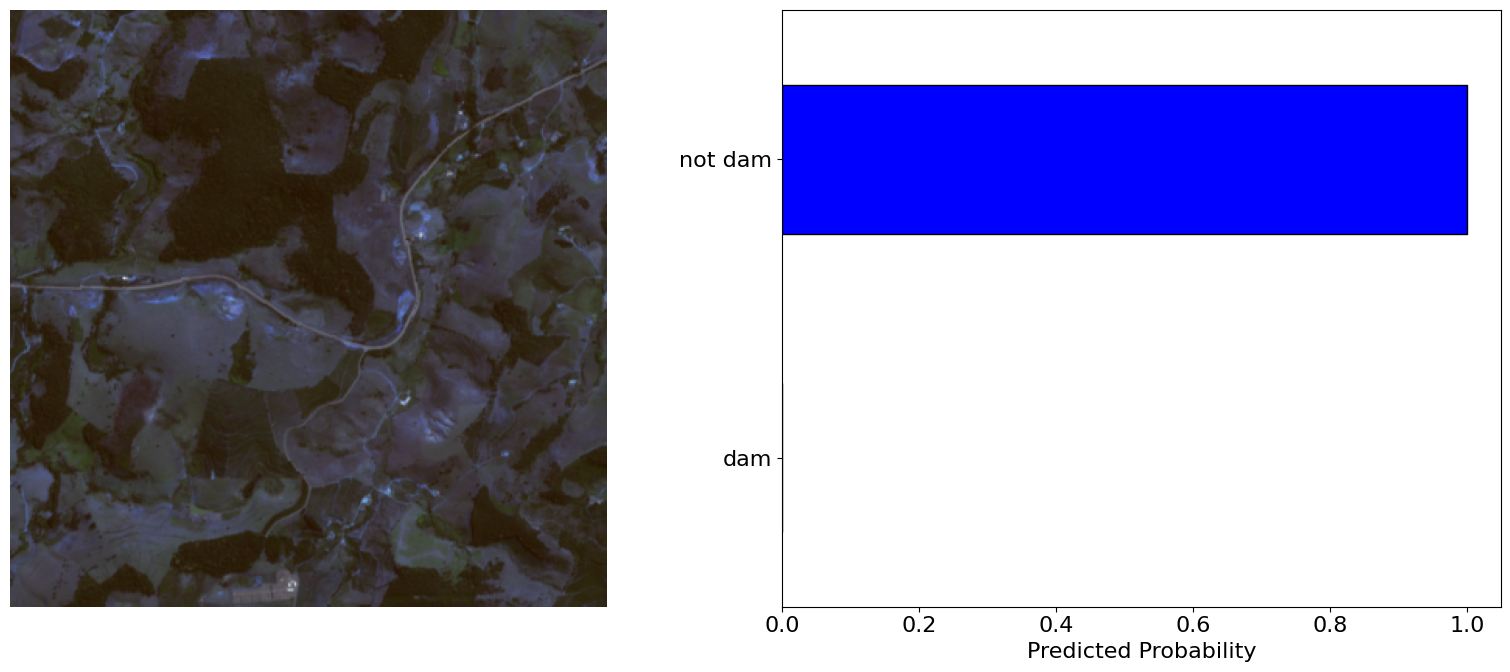

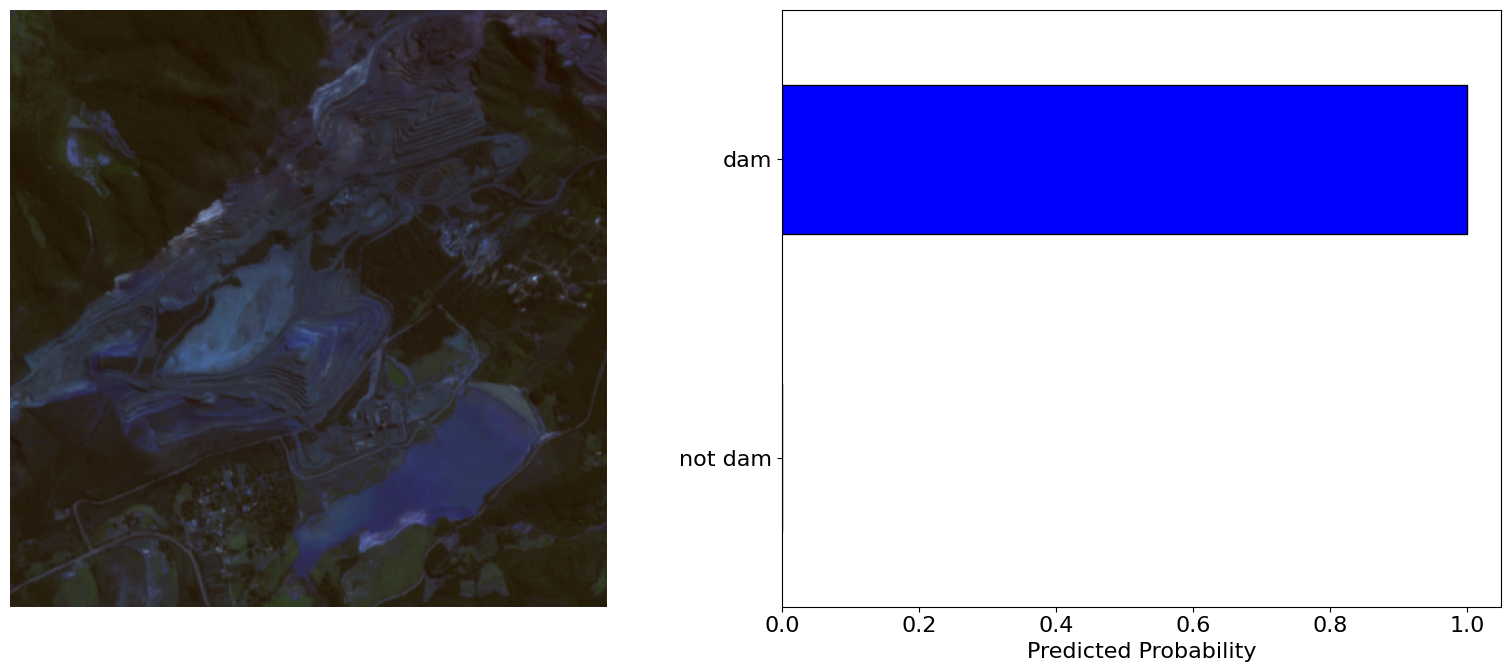

In [37]:
labels = ["not dam","dam"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/BrazilDAM/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/BrazilDAM/sentinel/2016/barragem/765_2016.tif')
image = image[:,:,1:4]
img_min, img_max = image.min(), image.max()
image = (image - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/BrazilDAM/sentinel/2017/nao_barragem/N114_2017.tif')
image = image[:,:,1:4]
img_min, img_max = image.min(), image.max()
image = (image - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/BrazilDAM/sentinel/2019/barragem/131_2019.tif')
image = image[:,:,1:4]
img_min, img_max = image.min(), image.max()
image = (image - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_image(image, labels, transform)